### Get data

In [2]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

import tensorflow as tf

2025-03-31 18:47:40.418949: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-31 18:47:40.419396: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-31 18:47:40.422266: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-03-31 18:47:40.429576: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-03-31 18:47:40.441632: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

In [3]:
x = np.array([8, 17, 23, 25, 29, 36,  14, 19, 31, 33])  # i
y = np.array([4, 11, 14, 15, 18, 21,  10, 12, 22, 23])  # r

sigma_x = np.full(x.shape, 0.5)
sigma_y = np.full(x.shape, 0.7)

### Fit

In [4]:
def fit_model(x, y):
    """Modello di fit lineare."""
    return x/y

In [6]:
epochs = 3

In [7]:
# Convert x to TensorFlow tensor
x_tf = tf.convert_to_tensor(x, dtype=tf.float64)

# Compute the first fit (ignoring errors on x)
popt, pcov = curve_fit(fit_model, x, y, sigma=sigma_y)

# Define a function to compute the derivative of the model
def compute_derivative(x_val, params):
    with tf.GradientTape() as tape:
        tape.watch(x_val)
        y_pred = fit_model(x_val, *params)
    return tape.gradient(y_pred, x_val)  # Compute dy/dx

# Iteratively update errors and refit
for i in range(epochs):
    # Compute the propagated error using automatic differentiation
    df_dx = compute_derivative(x_tf, popt).numpy()  # Convert TF tensor to NumPy array
    sigma_eff = np.sqrt(sigma_y**2 + (df_dx * sigma_x)**2)  # Total effective error
    
    # Refit with updated sigma_eff
    popt, pcov = curve_fit(fit_model, x, y, sigma=sigma_eff)
    
    # Compute chi-square
    chisq = np.sum(((y - fit_model(x, *popt)) / sigma_eff) ** 2)
    
    # Print results
    print(f'Step {i + 1}...')
    print(f'Parameters: {popt}')
    print(f'Errors: {np.sqrt(np.diag(pcov))}')
    print(f'Chi-square: {chisq:.2f} \n')

Step 1...
Parameters: [1.56157882]
Errors: [0.04184813]
Chi-square: 27.96 

Step 2...
Parameters: [1.56157882]
Errors: [0.04184813]
Chi-square: 27.96 

Step 3...
Parameters: [1.56157882]
Errors: [0.04184813]
Chi-square: 27.96 



### Plot

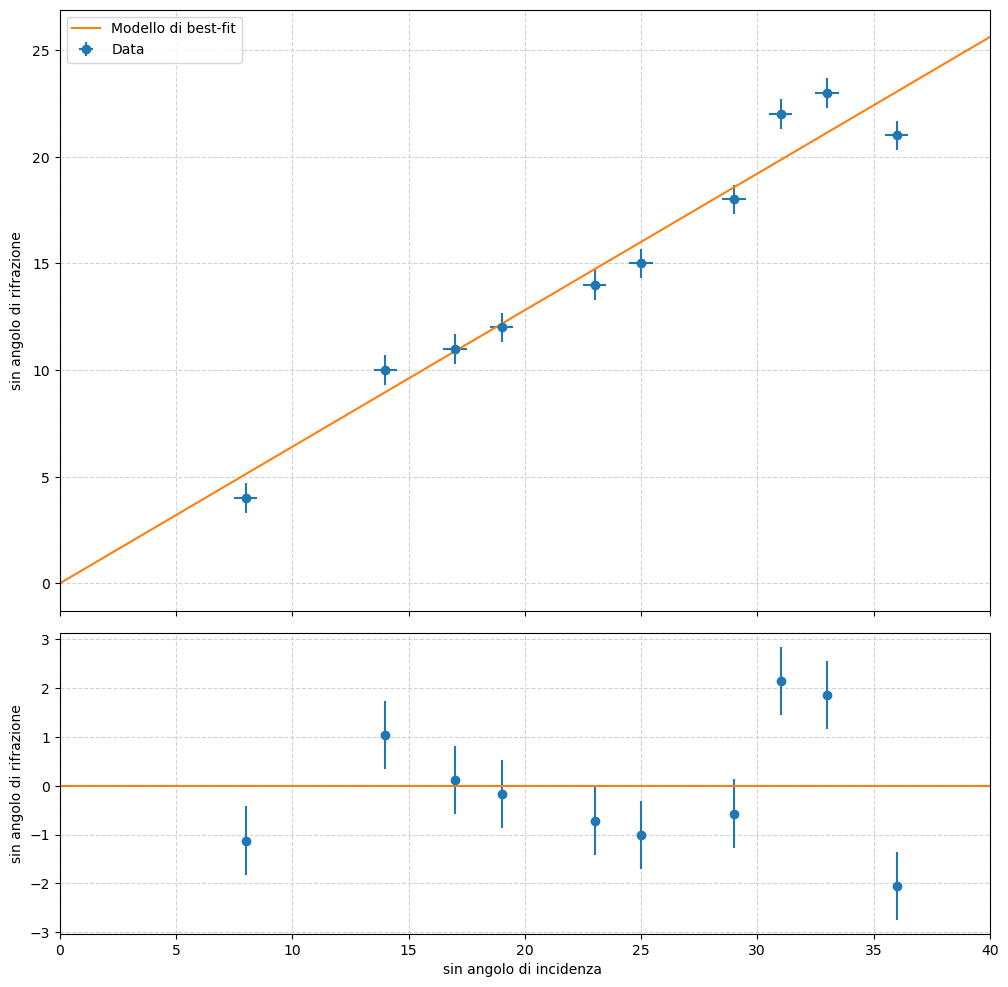

In [8]:
# x, y, sigma_x, sigma_y
# have popt, pcov

res = y - fit_model(x, *popt)

# Create the main figure...
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Data')
xgrid = np.linspace(0.0, 40.0, 100)
ax1.plot(xgrid, fit_model(xgrid, *popt), label='Modello di best-fit')

# Setup the axes, grids and legend.
ax1.set_ylabel('sin angolo di rifrazione')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# Setup the axes, grids and legend.
ax2.set_xlabel('sin angolo di incidenza ')
ax2.set_ylabel('sin angolo di rifrazione')
ax2.grid(color='lightgray', ls='dashed')

# The final touch to main canvas
plt.xlim(0.0, 40.0)
fig.align_ylabels((ax1, ax2))

plt.show()
